# Arthur Avom, Lorient, fin de contrat en juin 2027 : prolonger ou partir ?

Je me mets à la place de l'agent du joueur. Il reste huit mois de contrat, le mercato d'hiver ouvre dans deux mois, et à partir du 1er janvier un club étranger pourra lui faire signer un pré-contrat. L'agent doit savoir ce que vaut son joueur, à quel prix des profils proches sont partis cet été, et ce que chaque option rapporte ou coûte à chacun.

Ce notebook prépare la note de deux pages qui est dans `notes/`. Tout ce qui n'est pas mesuré dans les données est écrit comme une hypothèse.

**Point de départ, vérifié le 2 novembre 2026.** Avom figure toujours dans la liste des 86 joueurs de Ligue 1 en fin de contrat en 2027 publiée par [Foot-sur7 le 17 octobre 2026](https://www.foot-sur7.fr/787686-fin-de-contrat-2027-ligue-1). En juillet, Lorient avait levé l'option d'un an qui prolongeait son contrat jusqu'en 2027 et demandait environ 15 M€ ([L'Attaquant, 10 juillet 2026](https://www.lattaquant.com/mercato-arthur-avom-vers-un-gros-transfert-cet-ete/)). Je n'ai pas accès à son contrat : je raisonne en scénarios, sans inventer de clauses.

| Données | Ce que j'en tire | Date |
|---|---|---|
| Transfermarkt (jeu de données Football Data from Transfermarkt, CC0) | cotes, historique, fins de contrat | cotes au 1er juin 2026 |
| Mon modèle de prédiction ([prediction-valeur-joueurs](https://github.com/jmeignen/prediction-valeur-joueurs)) | fourchette de cote au 30 juin 2027 | entraîné en octobre 2026 |
| Statistiques de match 2025-26 (export FBref, non republié) | temps de jeu, récupérations, passes attendues | saison close le 17 mai 2026 |
| Presse sportive, liens dans `donnees/transferts_comparables_ete_2026.csv` | montants des transferts de l'été 2026 | consultée le 2 novembre 2026 |

Une cote Transfermarkt est une estimation faite par les contributeurs du site. Je m'en sers comme d'un repère, et je la compare aux montants réellement annoncés.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# mes couleurs pour ce projet : bleu pour les données, ambre pour Avom, gris pour le contexte
BLEU, AMBRE, GRIS, ENCRE, PAPIER = "#1F5FA0", "#C2780A", "#A3ACB9", "#14213D", "#F7F4EE"
plt.rcParams.update({
    "figure.facecolor": PAPIER, "axes.facecolor": PAPIER, "savefig.facecolor": PAPIER,
    "axes.edgecolor": GRIS, "axes.labelcolor": ENCRE, "xtick.color": ENCRE, "ytick.color": ENCRE,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": "#E3DED3", "grid.linewidth": 0.8, "font.size": 10, "axes.titleweight": "bold",
    "axes.titlesize": 11, "axes.titlelocation": "left",
})

AVOM = 1074628
joueurs = pd.read_csv("donnees/joueurs_ligue1_transfermarkt.csv")
cotes = pd.read_csv("donnees/historique_cotes_cas_et_comparables.csv", parse_dates=["date"])
pred = pd.read_csv("donnees/predictions_2027_ligue1.csv")
matchs = pd.read_csv("donnees/apparitions_ligue1_2025_26.csv")
comp = pd.read_csv("donnees/transferts_comparables_ete_2026.csv")

## 1. Le joueur

In [2]:
fiche = joueurs[joueurs.player_id == AVOM].iloc[0]
age = (pd.Timestamp("2026-11-02") - pd.Timestamp(fiche.date_of_birth)).days / 365.25
print(f"{fiche['name']}, {fiche.sub_position}, {fiche.country_of_citizenship}, {age:.1f} ans")
print(f"Club : {fiche.current_club_name}, contrat jusqu'au {fiche.contract_expiration_date[:10]}")
print(f"Cote Transfermarkt au 1er juin 2026 : {fiche.market_value_in_eur/1e6:.0f} M€ ; sélections : {fiche.international_caps:.0f}")

fin_2027 = joueurs.contract_expiration_date.str[:4].eq("2027")
print(f"Il fait partie des {fin_2027.sum()} joueurs de Ligue 1 de mes données dont le contrat se termine en 2027.")
print(f"Classé par cote, il est {joueurs[fin_2027].market_value_in_eur.rank(ascending=False)[fiche.name]:.0f}e de cette liste.")

Arthur Avom, Central Midfield, Cameroon, 21.9 ans
Club : FC Lorient, contrat jusqu'au 2027-06-30
Cote Transfermarkt au 1er juin 2026 : 20 M€ ; sélections : 14
Il fait partie des 148 joueurs de Ligue 1 de mes données dont le contrat se termine en 2027.
Classé par cote, il est 3e de cette liste.


Sa cote a presque triplé en huit mois. C'est la première chose que je regarde, parce que c'est elle qui fait monter l'enjeu pour Lorient : un joueur à 7 M€ qui part libre, c'est une perte ; à 20 M€, c'est une saison de budget.

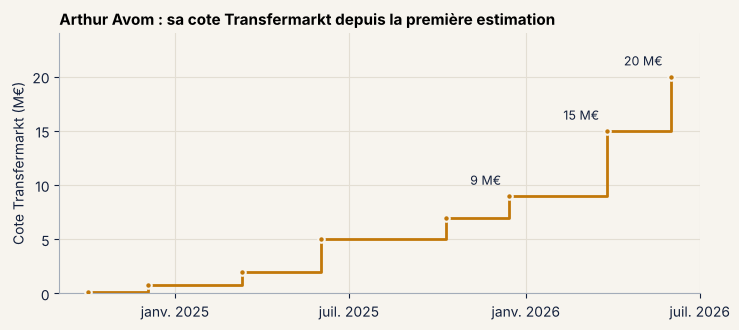

In [3]:
h = cotes[(cotes.player_id == AVOM) & (cotes.date >= "2023-07-01")].sort_values("date")
fig, ax = plt.subplots(figsize=(7.5, 3.4))
ax.step(h.date, h.market_value_in_eur / 1e6, where="post", color=AMBRE, lw=2)
ax.scatter(h.date, h.market_value_in_eur / 1e6, color=AMBRE, s=22, zorder=3, edgecolor=PAPIER, linewidth=1.5)
for d, v in zip(h.date.tail(3), h.market_value_in_eur.tail(3) / 1e6):
    ax.annotate(f"{v:.0f} M€", (d, v), textcoords="offset points", xytext=(-6, 8), ha="right", color=ENCRE, fontsize=9)
ax.set_ylabel("Cote Transfermarkt (M€)")
ax.set_title("Arthur Avom : sa cote Transfermarkt depuis la première estimation")
ax.set_ylim(0, 24)
import matplotlib.dates as mdates
ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 7]))
mois = {1: "janv.", 7: "juil."}
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{mois[mdates.num2date(x).month]} {mdates.num2date(x).year}"))
fig.tight_layout(); fig.savefig("figures/1_cote_avom.png", dpi=180); plt.show()

## 2. Sa saison 2025-26

Je compare Avom aux milieux de Ligue 1 qui ont joué au moins 900 minutes. Trois indicateurs seulement, ceux qu'un agent peut défendre devant un directeur sportif : ce qu'il récupère, ce qu'il crée, et la note moyenne de ses matchs.

In [4]:
lorient = matchs[matchs.player_id == AVOM]
matchs_club = 34  # 18 clubs, 34 journées
print(f"Ligue 1 2025-26 : {len(lorient)} matchs, {lorient.minutes_played.sum()} minutes, "
      f"{lorient.goals.sum()} buts, {lorient.assists.sum()} passe décisive")
print(f"Soit {lorient.minutes_played.sum() / (matchs_club * 90):.0%} des minutes possibles de Lorient")

stats = pd.read_csv("donnees/stats_ligue1_2025_26.csv")
mil = stats[(stats.position == "M") & (stats.minutes_played >= 900)].copy()
mil["recuperations_90"] = (mil.tackles + mil.interceptions) / mil.minutes_played * 90
mil["passes_attendues_90"] = mil.expected_assists / mil.minutes_played * 90
mil["buts_attendus_90"] = mil.expected_goals / mil.minutes_played * 90
indicateurs = {"recuperations_90": "Tacles + interceptions / 90 min",
               "passes_attendues_90": "Passes décisives attendues (xA) / 90 min",
               "buts_attendus_90": "Buts attendus (xG) / 90 min",
               "rating": "Note moyenne des matchs"}
lui = mil[mil.player_id == 1465307].iloc[0]  # son identifiant dans l'export FBref
tableau = pd.DataFrame({
    "Avom": [lui[c] for c in indicateurs],
    "Médiane des milieux": [mil[c].median() for c in indicateurs],
    "Rang centile": [(mil[c] < lui[c]).mean() * 100 for c in indicateurs],
}, index=indicateurs.values()).round(2)
print(f"{len(mil)} milieux comparés")
tableau

Ligue 1 2025-26 : 31 matchs, 2115 minutes, 2 buts, 1 passe décisive
Soit 69% des minutes possibles de Lorient
92 milieux comparés


,Avom,Médiane des milieux,Rang centile
Tacles + interceptions / 90 min,3.72,2.82,80.43
Passes décisives attendues (xA) / 90 min,0.13,0.12,58.70
Buts attendus (xG) / 90 min,0.05,0.10,18.48
Note moyenne des matchs,7.03,6.86,80.43


Lecture : un milieu qui récupère beaucoup (mieux que 8 milieux sur 10) et crée correctement, mais qui ne marque pas. C'est un profil de sentinelle ou de relayeur. Pour la note, ça compte : on ne le vendra pas sur ses buts, on le vendra sur son volume défensif et son âge.

Limite : une saison, 92 joueurs, et des statistiques qui dépendent du style de jeu de Lorient. Je m'en tiens à décrire ses chiffres.

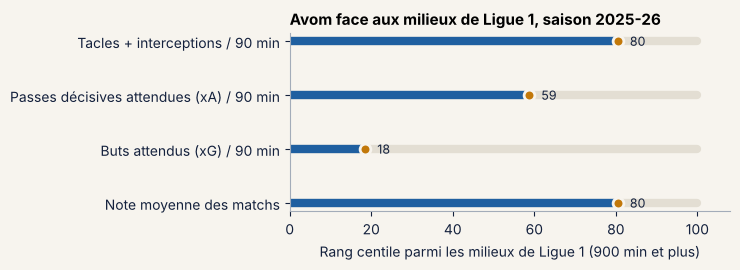

In [5]:
fig, ax = plt.subplots(figsize=(7.5, 2.8))
lignes = list(indicateurs.values())
y = np.arange(len(lignes))[::-1]
ax.hlines(y, 0, 100, color="#E3DED3", lw=6, capstyle="round")
ax.hlines(y, 0, tableau["Rang centile"], color=BLEU, lw=6, capstyle="round")
ax.scatter(tableau["Rang centile"], y, color=AMBRE, s=60, zorder=3, edgecolor=PAPIER, linewidth=2)
for yi, v in zip(y, tableau["Rang centile"]):
    ax.text(v + 3, yi, f"{v:.0f}", va="center", color=ENCRE, fontsize=9)
ax.set_yticks(y, lignes); ax.set_xlim(0, 108); ax.grid(False)
ax.set_xlabel("Rang centile parmi les milieux de Ligue 1 (900 min et plus)")
ax.set_title("Avom face aux milieux de Ligue 1, saison 2025-26")
fig.tight_layout(); fig.savefig("figures/2_centiles_avom.png", dpi=180); plt.show()

## 3. La valeur, sous forme de fourchette

Mon modèle prédit la cote au 30 juin 2027 avec une fourchette qui contient la vraie cote 8 fois sur 10 (79 % sur la saison test 2025-26). Pour un joueur typique, il se trompe d'un facteur 1,30 environ : à 20 M€, ça veut dire qu'une erreur de 15 à 26 M€ est banale.

Ce que le modèle ne sait pas : qu'il ne reste qu'un an de contrat. Il prédit la cote d'un joueur sans tenir compte de son contrat. C'est pour ça que la partie 4 compte plus que celle-ci.

In [6]:
p = pred[pred.tm_id == AVOM].iloc[0]
fourchette = pd.Series({"Bas (10 %)": p.bas_2027, "Central": p.cote_2027, "Haut (90 %)": p.haut_2027}) / 1e6
print(f"Cote au 1er juin 2026 : {p.cote_2026/1e6:.0f} M€")
print("Cote prédite au 30 juin 2027 (M€) :")
print(fourchette.round(1).to_string())
print(f"Évolution centrale : {p.evolution_pct:+.0f} %, portée surtout par son âge (21 ans).")

Cote au 1er juin 2026 : 20 M€
Cote prédite au 30 juin 2027 (M€) :
Bas (10 %)     13.1
Central        23.6
Haut (90 %)    42.5
Évolution centrale : +18 %, portée surtout par son âge (21 ans).


## 4. Les comparables : ce que les clubs ont vraiment payé cet été

Six joueurs de Ligue 1 vendus entre juin et septembre 2026 alors qu'il leur restait un an de contrat, comme Avom. Je n'ai pas trouvé assez de milieux de son âge, donc j'ai élargi aux attaquants et aux latéraux : ce qui les rapproche, c'est la situation de leur contrat. Les montants viennent de la presse (lien pour chacun dans le fichier), certains ne sont pas officiels.

Je compare le montant fixe à la cote Transfermarkt du 1er juin 2026.

In [7]:
c = comp.merge(joueurs[["player_id", "date_of_birth", "market_value_in_eur"]], left_on="tm_id", right_on="player_id")
c["age_au_transfert"] = (pd.to_datetime(c.date_annonce) - pd.to_datetime(c.date_of_birth)).dt.days / 365.25
c["cote_juin_2026"] = c.market_value_in_eur / 1e6
c["prix_sur_cote"] = c.montant_fixe_meur / c.cote_juin_2026
vue = c[["joueur", "poste", "club_vendeur", "club_acheteur", "age_au_transfert", "cote_juin_2026",
         "montant_fixe_meur", "bonus_meur", "prix_sur_cote", "source"]].sort_values("prix_sur_cote", ascending=False)
vue.round(2)

,joueur,poste,club_vendeur,club_acheteur,age_au_transfert,cote_juin_2026,montant_fixe_meur,bonus_meur,prix_sur_cote,source
3,Jacques Ekomié,Défenseur,Angers SCO,Wrexham,23.02,9.0,9.3,NaN,1.03,Maxifoot
0,Pablo Pagis,Attaquant,FC Lorient,Paris FC,23.54,15.0,15.0,1.5,1.00,info.fr
4,Caio Henrique,Défenseur,AS Monaco,Ajax,28.91,12.0,11.0,3.0,0.92,info.fr
1,Yann Gboho,Attaquant,FC Toulouse,Coventry City,25.64,18.0,15.0,NaN,0.83,AfricaSoccer citant Foot Mercato
2,Lassine Sinayoko,Attaquant,AJ Auxerre,Paris FC,26.62,10.0,8.0,NaN,0.80,beIN Sports
5,Tom Louchet,Milieu,OGC Nice,PAOK,23.25,7.0,2.0,NaN,0.29,Maxifoot


In [8]:
r = c.prix_sur_cote
print(f"Prix fixe / cote : médiane {r.median():.2f}, de {r.min():.2f} à {r.max():.2f}")
sans_louchet = r[c.joueur != "Tom Louchet"]
print(f"Sans Tom Louchet (vendu 2 M€ pour une cote de 7 M€) : de {sans_louchet.min():.2f} à {sans_louchet.max():.2f}")

Prix fixe / cote : médiane 0.88, de 0.29 à 1.03
Sans Tom Louchet (vendu 2 M€ pour une cote de 7 M€) : de 0.80 à 1.03


Cinq fois sur six, le club vendeur a obtenu entre 80 % et un peu plus de 100 % de la cote, même à un an de la fin du contrat. Le sixième cas rappelle que ça peut très mal tourner : Nice a laissé partir Tom Louchet pour environ 2 M€, moins d'un tiers de sa cote. Je ne connais pas les raisons (temps de jeu, volonté du joueur, besoin de vendre), donc je ne les invente pas.

Six transferts, c'est trop peu pour une règle. Je m'en sers comme d'un ordre de grandeur pour l'été, pas comme d'une formule.

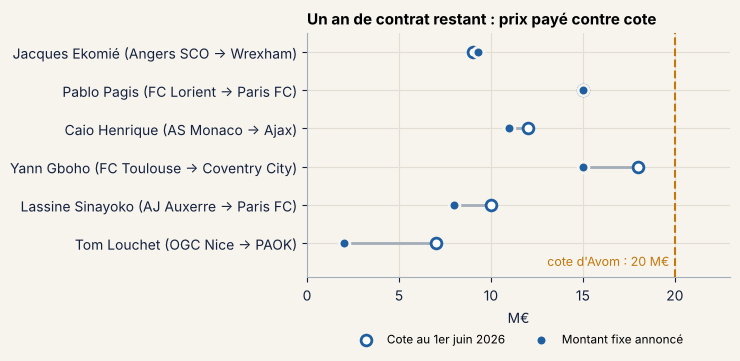

In [9]:
v = c.sort_values("prix_sur_cote")
fig, ax = plt.subplots(figsize=(7.5, 3.8))
y = np.arange(len(v))
ax.hlines(y, v.montant_fixe_meur, v.cote_juin_2026, color=GRIS, lw=2)
ax.scatter(v.cote_juin_2026, y, color="white", edgecolor=BLEU, s=60, linewidth=2, zorder=3, label="Cote au 1er juin 2026")
ax.scatter(v.montant_fixe_meur, y, color=BLEU, s=60, zorder=3, edgecolor=PAPIER, linewidth=2, label="Montant fixe annoncé")
ax.set_yticks(y, [f"{j} ({cv} → {ca})" for j, cv, ca in zip(v.joueur, v.club_vendeur, v.club_acheteur)])
ax.axvline(20, color=AMBRE, lw=1.5, ls="--")
ax.set_ylim(-0.9, len(v) - 0.5)
ax.text(19.7, -0.6, "cote d'Avom : 20 M€", color=AMBRE, fontsize=9, ha="right")
ax.set_xlabel("M€"); ax.set_xlim(0, 23)
ax.set_title("Un an de contrat restant : prix payé contre cote")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=2, frameon=False, fontsize=8.5)
fig.tight_layout(); fig.savefig("figures/3_comparables.png", dpi=180); plt.show()

## 5. Les scénarios

Quatre options. Pour chacune, ce que touche Lorient, ce que gagne le joueur, ce que ça change pour l'agent. Les montants viennent de la partie 4 quand c'est possible ; sinon ce sont des **hypothèses**, signalées comme telles et faciles à changer dans la cellule ci-dessous.

Le salaire actuel est une estimation de SalarySport (13 000 £ par semaine, environ 676 000 £ par an).

In [10]:
COTE = 20.0                      # M€, cote au 1er juin 2026
ratio_ete = r.median()            # mesuré sur les 6 comparables
ratio_ete_bas = sans_louchet.min()
DECOTE_HIVER = (0.5, 0.8)         # HYPOTHÈSE : en janvier, il ne reste que 6 mois ; je n'ai aucun comparable pour la mesurer
SALAIRE_ACTUEL = 0.676 * 1.15     # M€ brut par an, estimation SalarySport convertie à 1,15 €/£ (hypothèse de change)

scenarios = pd.DataFrame([
    ["Prolonger (jusqu'en 2030)", "0 aujourd'hui ; garde un joueur coté 13 à 42 M€ en 2027 (modèle)",
     "hausse de salaire négociée, sécurité", "commission sur le nouveau contrat ; joueur bloqué tant que le club ne veut pas vendre"],
    ["Vendre cet hiver (janvier 2027)", f"{COTE*DECOTE_HIVER[0]:.0f} à {COTE*DECOTE_HIVER[1]:.0f} M€ (hypothèse)",
     "nouveau contrat de 4 ou 5 ans, choix du club limité aux clubs prêts à payer", "commission sur le contrat ; fenêtre courte, peu d'acheteurs"],
    ["Vendre à l'été 2027", "0 sans prolongation : le contrat se termine le 30 juin 2027",
     "seulement s'il a prolongé avant (prolonger pour mieux vendre)", "suppose un accord écrit et homologué ; sinon, c'est le départ libre"],
    ["Partir libre (juillet 2027)", "0, hors indemnité de formation éventuelle",
     "prime à la signature et salaire plus hauts, puisque l'acheteur ne paie pas d'indemnité (à négocier)", "position la plus forte face aux clubs acheteurs ; risque si blessure d'ici là"],
], columns=["Scénario", "Ce que touche Lorient", "Ce que gagne le joueur", "Pour l'agent"])
print(f"Repère été 2026 : un club vendeur obtenait en médiane {ratio_ete:.2f} × la cote, soit {COTE*ratio_ete:.1f} M€ pour Avom,")
print(f"et au moins {COTE*ratio_ete_bas:.0f} M€ si l'on écarte le cas Louchet. Lorient demandait environ 15 M€ en juillet.")
scenarios

Repère été 2026 : un club vendeur obtenait en médiane 0.88 × la cote, soit 17.5 M€ pour Avom,
et au moins 16 M€ si l'on écarte le cas Louchet. Lorient demandait environ 15 M€ en juillet.


,Scénario,Ce que touche Lorient,Ce que gagne le joueur,Pour l'agent
0,Prolonger (jusqu'en 2030),0 aujourd'hui ; garde un joueur coté 13 à 42 M...,"hausse de salaire négociée, sécurité",commission sur le nouveau contrat ; joueur blo...
1,Vendre cet hiver (janvier 2027),10 à 16 M€ (hypothèse),"nouveau contrat de 4 ou 5 ans, choix du club l...","commission sur le contrat ; fenêtre courte, pe..."
2,Vendre à l'été 2027,0 sans prolongation : le contrat se termine le...,seulement s'il a prolongé avant (prolonger pou...,"suppose un accord écrit et homologué ; sinon, ..."
3,Partir libre (juillet 2027),"0, hors indemnité de formation éventuelle","prime à la signature et salaire plus hauts, pu...",position la plus forte face aux clubs acheteur...


Une précision sur la ligne « vendre à l'été 2027 » : sans prolongation, cette option n'existe pas pour le club. Le contrat se termine le 30 juin 2027, donc il n'y a plus rien à vendre en juillet. C'est le cœur du rapport de force, et c'est pour ça que le mercato de janvier est la dernière vraie fenêtre de Lorient.

La commission de l'agent est plafonnée à 10 % du montant du contrat qu'il a permis de conclure (Code du sport, art. L. 222-17). Pour donner un ordre d'idée, voici ce plafond selon la valeur du contrat signé. Les salaires testés sont des hypothèses : je ne connais aucune offre.

In [11]:
salaires = [SALAIRE_ACTUEL, 1.5, 2.5]   # M€ brut par an : l'actuel, puis deux hypothèses
duree = 4
plafond = pd.DataFrame({
    "Salaire brut annuel (M€)": salaires,
    "Contrat sur 4 ans (M€)": [s * duree for s in salaires],
    "Plafond de commission, 10 % (M€)": [s * duree * 0.10 for s in salaires],
}, index=["Salaire actuel estimé", "Hypothèse 1", "Hypothèse 2"]).round(2)
plafond

,Salaire brut annuel (M€),Contrat sur 4 ans (M€),"Plafond de commission, 10 % (M€)"
Salaire actuel estimé,0.78,3.11,0.31
Hypothèse 1,1.50,6.00,0.60
Hypothèse 2,2.50,10.00,1.00


## 6. Le cadre juridique

Ce que l'agent doit avoir en tête avant de négocier. J'ai vérifié chaque point sur la source indiquée au 2 novembre 2026 ; les numéros d'articles sont à revérifier sur Légifrance ou dans les règlements de la saison en cours avant toute utilisation réelle.

**L'agent lui-même**

| Règle | Où | Ce que ça change ici |
|---|---|---|
| Rémunération plafonnée à 10 % du montant du contrat conclu ; plafond commun si plusieurs agents interviennent | Code du sport, art. L. 222-17 | voir le tableau de la partie 5 |
| Carte professionnelle obligatoire, formation, déclaration à la fédération de toute somme versée ou perçue | Code du sport, art. L. 222-7, modifié par la loi n° 2026-725 du 3 août 2026, en vigueur le 5 août | l'agent d'Avom doit être en règle avant de signer quoi que ce soit |
| Un superviseur peut être payé sur une part de la commission, pour des tâches de prospection et de rapports, pendant trois ans après son contrat | Code du sport, art. L. 222-12-1 (loi du 3 août 2026), lecture de [Kohen Avocats](https://kohenavocats.com/recruteur-scout-football-independant-requalification-prime-signature-agent-sportif-2026/) | c'est exactement le type de dossier qu'un superviseur prépare |
| Plafonds de commission FIFA : suspendus dans le monde entier depuis la circulaire du 30 décembre 2023 | Règlement FIFA sur les agents de football, état décrit par [Forefront Legal](https://www.forefrontlegal.com/post/fifa-s-agent-rules-remain-in-legal-limbo-the-status-of-the-ffar-mid-2026) (juin 2026) | côté FIFA, pas de plafond appliqué pour l'instant ; en France, le plafond du Code du sport reste applicable |

**Le contrat et le transfert**

| Point de négociation | Règle | Où |
|---|---|---|
| Durée d'une prolongation | 5 ans au maximum pour un contrat de sportif professionnel | Code du sport, art. L. 222-2-4 ; RSTP, art. 18.2 |
| Pré-contrat avec un club étranger | possible quand le contrat se termine dans les 6 mois, donc dès le 1er janvier 2027 | Règlement FIFA du statut et du transfert des joueurs (RSTP), art. 18.3 |
| Clause libératoire | une clause qui fixe à l'avance le prix de sortie n'est pas admise dans un contrat homologué par la LFP ; un accord parallèle non homologué est privé d'effet | Charte du football professionnel, art. 257 (clauses libératoires interdites, contrat refusé à l'homologation) et art. 256 (accord non soumis à homologation : sans effet s'il contredit le statut), [version 2023-2024](https://bo-cms.lfp.fr/-/media/Project/LFP/LFP/Documents/Charte-Foot-Pro/23-24-JOUEURS-CHARTE-30-06.pdf) ; analyse de [F. Guillaumond](https://consultation.avocat.fr/blog/frederic-guillaumond/article-24654-de-l-absence-d-effet-d-une-clause-liberatoire-sur-un-contrat-homologue-par-la-ligue-professionnelle-de-football.html) (2018) |
| Pourcentage à la revente | clause entre clubs, libre ; elle ne profite pas au joueur mais peut faire baisser le prix fixe, donc faciliter un départ | RSTP, art. 18ter (interdiction de la propriété par des tiers, qui ne vise pas les clubs) |
| Mécanisme de solidarité | 5 % de toute indemnité de transfert est reversé aux clubs formateurs | RSTP, art. 21 et annexe 5 |
| Indemnité de formation | peut être due en cas de départ à l'étranger jusqu'à la fin de la saison de ses 23 ans | RSTP, art. 20 et annexe 4 |
| Droit à l'image | une part de la rémunération peut être versée en redevance d'image, dans les conditions fixées par l'accord collectif | Code du sport, art. L. 222-2-10-1 |
| Rupture et indemnités | depuis l'arrêt Diarra (CJUE, 4 octobre 2024, C-650/22), la FIFA applique un régime provisoire pour l'article 17 | RSTP, art. 17, régime provisoire de décembre 2024 |

Ce que j'en retiens pour la négociation : comme la clause libératoire n'est pas une option en France, l'agent ne peut pas « acheter » un départ futur dans une prolongation. Ce qui se négocie, c'est le salaire, la durée, la part en droit à l'image, et un engagement de bonne foi du club qui n'a de valeur que s'il est écrit dans le contrat homologué.

## 7. Ce que je retiens, et ce que je ne sais pas

- Avom vaut aujourd'hui une vingtaine de millions sur Transfermarkt, et mon modèle place sa cote de juin 2027 entre 13 et 42 M€. La fourchette est large parce qu'il a 21 ans : c'est à cet âge que le modèle se trompe le plus.
- Cet été, les clubs de Ligue 1 ont vendu leurs joueurs à un an de la fin de contrat autour de 0,9 fois leur cote. Pour Avom, ce repère donne environ 17 à 18 M€, au-dessus des 15 M€ que Lorient demandait en juillet.
- En janvier, le prix baissera. De combien, je ne peux pas le mesurer avec mes données : je l'ai écrit comme une hypothèse.
- Le rapport de force penche vers le joueur à partir du 1er janvier, grâce au pré-contrat avec un club étranger.

Ce que je ne sais pas : son contrat réel, ses éventuelles blessures, ce que veut le joueur, les offres reçues. Une vraie note d'agent commencerait par ces quatre questions.